In [68]:
# Packages
import os, sys, ants
import numpy as np
import pandas as pd
import nibabel as nib
import dipy.reconst.fwdti as fwdti
import dipy.reconst.dti as dti
import matplotlib.pyplot as plt
from dipy.data import fetch_hbn
from dipy.segment.mask import median_otsu
from scipy.ndimage import shift
from scipy.ndimage import affine_transform
from dipy.core.gradients import gradient_table

In [2]:
# Parameters
sub = "sub-59600"
ses = "ses-sd"

# Paths
root = "/data/project/sleep_ENIGMA_glymphatic/enigma-sd/oslo-bids"
subs = pd.read_csv(f"{root}/participants.tsv", sep="\t")["participant_id"]
sessions = ["ses-ebl", "ses-sd"]

# Scan suffixes
dwi = f"{root}/derivatives/qsiprep/{sub}/{ses}/dwi/{sub}_{ses}_space-T1w"
anat = f"{root}/derivatives/qsiprep/{sub}/anat/{sub}"

In [3]:
# Function for plotting scans
def plot_dwi(dwi_data, seg_data = False):
    # Select a slice to plot
    slice_index = dwi_data.shape[2] // 2  # Middle slice for demonstration
    b0_volume = 0  # Typically, the first volume is the B0 image
    b0_slice = dwi_data[:, :, slice_index, b0_volume]
    if seg_data is not False:
        seg_slice = seg_data[:, :, slice_index]

    # Plot the selected slice
    plt.figure(figsize=(8, 8))
    plt.imshow(b0_slice.T, cmap='gray')
    if seg_data is not False:
        plt.imshow(seg_slice.T, cmap='inferno', alpha = 0.3)
    plt.title(f'DWI Slice {slice_index}, B0 Volume')
    plt.axis('off')
    plt.show()

In [4]:
# Function for plotting scans
def plot_scalar(img_data):
    # Select a slice to plot
    slice_index = img_data.shape[2] // 2  # Middle slice for demonstration
    img_slice = img_data[:, :, slice_index]

    # Plot the selected slice
    plt.figure(figsize=(8, 8))
    plt.imshow(img_slice.T, cmap='gray')
    plt.title(f'Scalar Slice {slice_index}')
    plt.axis('off')
    plt.show()

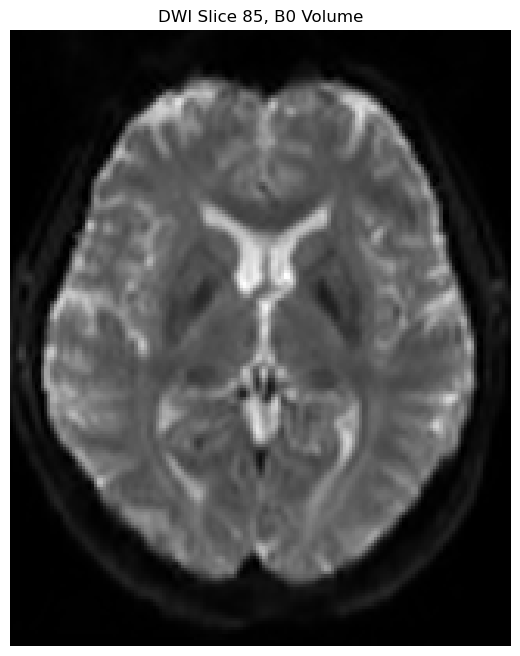

In [5]:
# Load DWI image and image data
img = nib.load(f"{dwi}_desc-preproc_dwi.nii.gz")
data = np.asarray(img.dataobj)
plot_dwi(data)

In [6]:
# Load gradient table
gtab = gradient_table(f"{dwi}_desc-preproc_dwi.bval", f"{dwi}_desc-preproc_dwi.bvec")

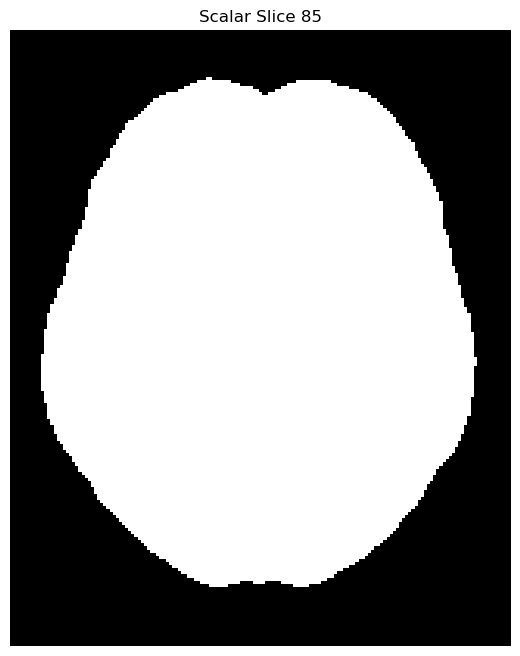

In [7]:
# Load mask and mask data
mask = nib.load(f"{dwi}_desc-brain_mask.nii.gz")
mask = mask.get_fdata()
plot_scalar(mask)

In [9]:
# Train FWDTI model
fwdtimodel = fwdti.FreeWaterTensorModel(gtab)
fwdtifit = fwdtimodel.fit(data, mask=mask)

  0%|          | 0/1462354.0 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# Obtain indices
FA = fwdtifit.fa # Fractional anisotropy
MD = fwdtifit.md # Mean diffusivity
FW = fwdtifit.f # Free water level

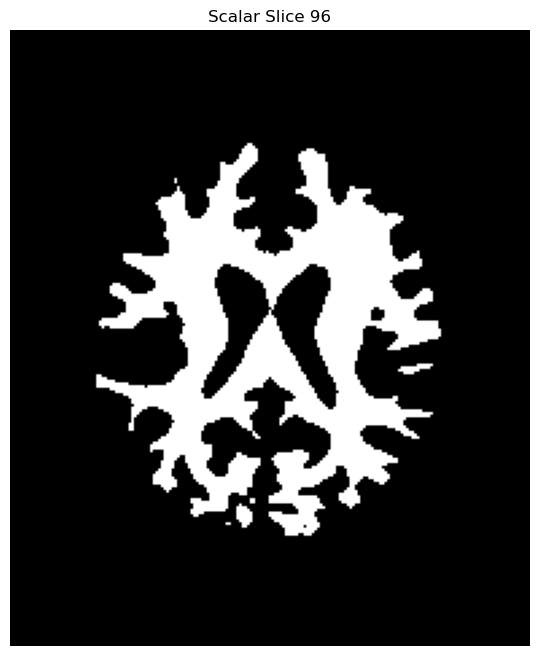

In [10]:
# Obtain WM segmentation
aseg = nib.load(f"{anat}_desc-aseg_dseg.nii.gz")
aseg_data = aseg.get_fdata()

WM_labels = [2, 41]
WM_data = np.isin(aseg_data, WM_labels).astype(np.uint8)
WM = nib.Nifti1Image(WM_data, aseg.affine)
plot_scalar(WM_data)

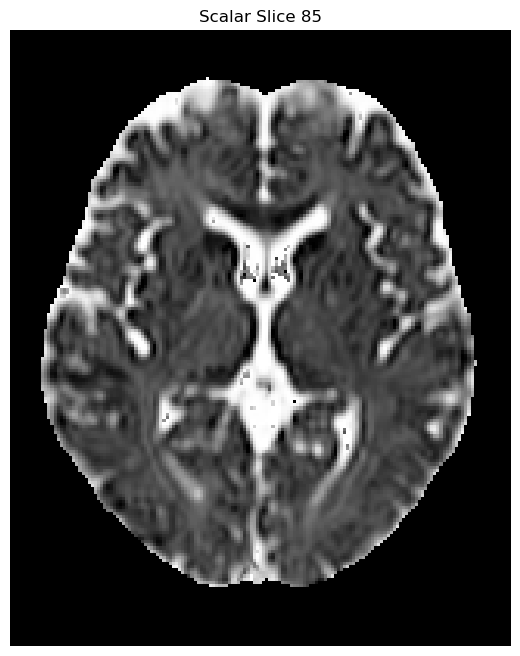

In [11]:
FW = nib.load(f"{dwi}_FW.nii.gz")
FW_data = FW.get_fdata()
plot_scalar(FW_data)

In [15]:
print(img.shape)
print(mask.shape)
print(FW.shape)
print(WM.shape)

(161, 198, 171, 204)
(161, 198, 171)
(161, 198, 171)
(193, 229, 193)


In [37]:
tf_mat = np.linalg.inv(FW.affine).dot(WM.affine)

In [44]:
WMRS_data = affine_transform(
    WM_data,
    tf_mat[:3, :3],
    offset=tf_mat[:3, 3],
    output_shape=FW.shape,
    order=1
)

In [47]:
WMRS = nib.Nifti1Image(WMRS_data, FW.affine)
nib.save(WMRS, f"{anat}_WMRS.nii.gz")

In [66]:
# Center Crop
dist = [c / 2 for c in FW.shape]
coords = [c / 2 for c in WM.shape]

x_start, x_end = int(coords[0]-dist[0]), int(coords[0]+dist[0]) # Center Crop
y_start, y_end = int(coords[1]-dist[1]), int(coords[1]+dist[1])
z_start, z_end = int(0), int(FW.shape[2])

(161, 198, 171)


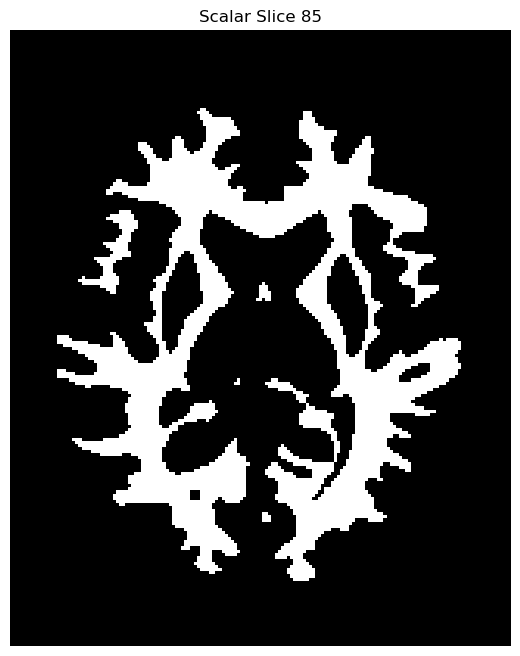

In [75]:
#WMC = WM.slicer[x_start:x_end, y_start:y_end, z_start:z_end]

WMC_data = WM_data[x_start:x_end, y_start:y_end, z_start:z_end] # Crop in the right shape
#WMC_data = shift(WMC_data, shift=(0, 0, 2), mode='nearest') # Z-shift by 2 voxels to obtain right alignment
WMC = nib.Nifti1Image(WMC_data, FW.affine)

print(WMC.shape)
plot_scalar(WMC_data)
nib.save(WMC, f"{anat}_space-DWI_WM.nii.gz")

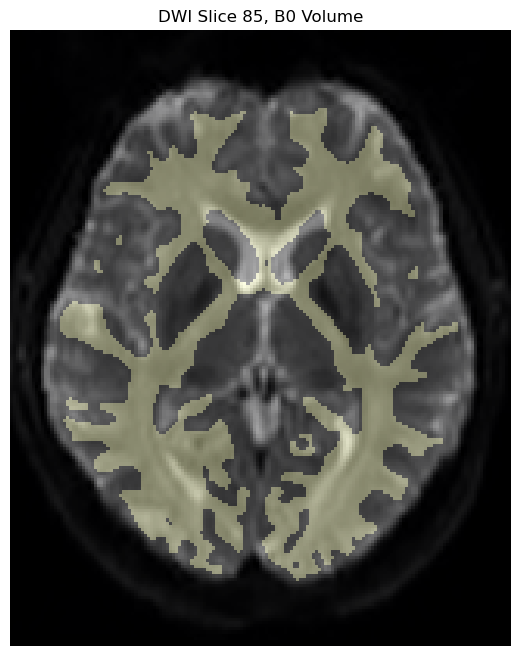

In [71]:
plot_dwi(data, WMC_data)

In [147]:
ref = nib.load(f"{dwi}_dwiref.nii.gz")
ref.shape

(193, 229, 193)

In [144]:
fi = ants.image_read(f"{dwi}_dwiref.nii.gzz")
mo = ants.image_read(f"{anat}_desc-preproc_T1w.nii")

xfm = ants.registration(fixed=fi, moving=mo, type_of_transform='Rigid', outprefix=f"{root}/derivatives/qsiprep/{sub}/anat/")

mo2 = ants.image_read(f"{anat}_desc-aseg_dseg.nii")
moved = ants.apply_transforms(fi, mo2, transformlist=xfm['fwdtransforms'], interpolator='lanczosWindowedSinc', imagetype=3)

ants.image_write(moved, f"{anat}_desc-aseg_reg.nii.gz")

AttributeError: module 'ants' has no attribute 'image_read'